In [28]:
import os
os.chdir(r'C:\Users\gonza\Desktop\Desafío Latam\G76\6. Modelos Avanzados y Redes Neuronales\7. 30-10-2024\Spam Detection')
os.listdir()

['spam.csv']

In [29]:
# Lectura y manejo básico de datos

import pandas as pd
import numpy as np

In [36]:
# Procesamiento de textos

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from keras.models import Model
from keras.layers import LSTM, Activation, Dense, Dropout, Input, Embedding
from keras.optimizers import RMSprop
from keras.preprocessing.text import Tokenizer
from keras.preprocessing import sequence
from keras.utils import to_categorical
from keras.callbacks import EarlyStopping
%matplotlib inline

from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer

In [37]:
df = pd.read_csv('spam.csv')

df.head(5)

,label,sms
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5572 non-null   object
 1   sms     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


Text(0.5, 1.0, 'Mensajes SPAM y HAM')

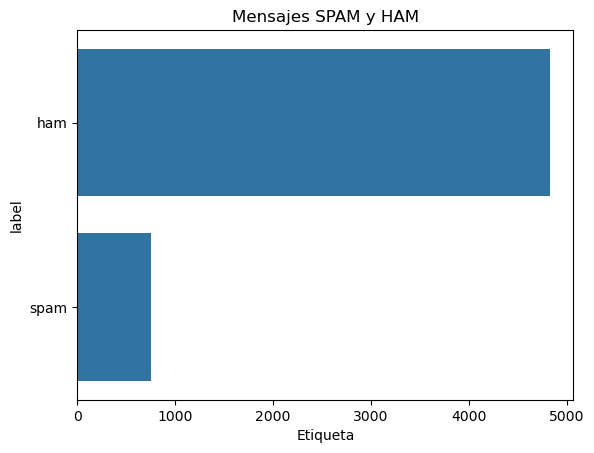

In [40]:
sns.countplot(df.label)
plt.xlabel('Etiqueta')
plt.title('Mensajes SPAM y HAM')

In [42]:
# Stemming y stopwords

stop_words = stopwords.words('english')
stemmer = SnowballStemmer('english')

In [43]:
text_cleaning_re = "@\S+|A-Za-z0-9]+"

def preprocess(text, stem=False):
    text = re.sub(text_cleaning_re, ' ', str(text).lower()).strip()
    tokens = []
    for token in text.split():
        if token not in stop_words:
            if stem:
                tokens.append(stemmer.stem(token))
            else:
                tokens.append(token)
    return " ".join(tokens)

In [119]:
# Procesamiento de las categorías

from sklearn.preprocessing import LabelEncoder
X = df.sms
Y = df.label
le = LabelEncoder() # Transformamos la variable respuesta

# Label Encoder Asigna un valor numérico único a cada categoría
# one Hot Encoder (get_dummies) Crea columnas binarias para cada categoría, donde solo una columna es “1” y el resto “0” para cada observación
Y = le.fit_transform(Y)
Y = Y.reshape(-1,1)

In [55]:
# train y test split

x_train, x_test, y_train, y_test = train_test_split(X,Y,test_size=0.25)

In [56]:
max_words = 1000 # Máximo de palabras
max_len = 150 # Largo máximo
tok = Tokenizer(num_words=max_words) # Tokenización para separar textos
tok.fit_on_texts(x_train)
sequences = tok.texts_to_sequences(x_train)
sequences_matrix = sequence.pad_sequences(sequences,maxlen=max_len)

In [57]:
# Generamos el modelo 

from tensorflow.keras.layers import Conv1D, Bidirectional, LSTM, Dense, Input, Dropout
from tensorflow.keras.layers import SpatialDropout1D
from tensorflow.keras.callbacks import ModelCheckpoint

In [58]:
# Función que genera el modelo

def RNN():
    inputs = Input(name='inputs',shape=[max_len])
    layer = Embedding(max_words,50,input_length=max_len)(inputs)
    layer = LSTM(64)(layer)
    layer = Dense(256,name='FC1')(layer)
    layer = Activation('relu')(layer) # Función de activación
    layer = Dropout(0.5)(layer)
    layer = Dense(1,name='out_layer')(layer) 
    layer = Activation('sigmoid')(layer) # Salida sigmoid
    model = Model(inputs=inputs,outputs=layer)
    return model

In [59]:
model = RNN()
model.summary()
model.compile(loss='binary_crossentropy', optimizer=RMSprop(), metrics=['accuracy'])

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 inputs (InputLayer)         [(None, 150)]             0         
                                                                 
 embedding_3 (Embedding)     (None, 150, 50)           50000     
                                                                 
 lstm_3 (LSTM)               (None, 64)                29440     
                                                                 
 FC1 (Dense)                 (None, 256)               16640     
                                                                 
 activation_2 (Activation)   (None, 256)               0         
                                                                 
 dropout_1 (Dropout)         (None, 256)               0         
                                                                 
 out_layer (Dense)           (None, 1)                 257 

In [60]:
model.fit(sequences_matrix,
          y_train,
          batch_size=128,
          epochs=10,
          validation_split=0.2,
          callbacks=[EarlyStopping(monitor='val_loss',min_delta=0.0001)])

Epoch 1/10


27/27 [==============================] - 11s 232ms/step - loss: 0.4278 - accuracy: 0.8522 - val_loss: 0.2641 - val_accuracy: 0.8672
Epoch 2/10
27/27 [==============================] - 6s 208ms/step - loss: 0.1777 - accuracy: 0.9426 - val_loss: 0.1330 - val_accuracy: 0.9665
Epoch 3/10
27/27 [==============================] - 6s 213ms/step - loss: 0.0801 - accuracy: 0.9812 - val_loss: 0.0909 - val_accuracy: 0.9737
Epoch 4/10
27/27 [==============================] - 5s 169ms/step - loss: 0.0506 - accuracy: 0.9871 - val_loss: 0.0983 - val_accuracy: 0.9737


In [62]:
# Preprocesamiento para el testing

test_sequences = tok.texts_to_sequences(x_test)
test_sequences_matrix = sequence.pad_sequences(test_sequences,maxlen=max_len)

In [92]:
accr = model.evaluate(test_sequences_matrix, y_test)

44/44 [==============================] - 1s 18ms/step - loss: 0.1015 - accuracy: 0.9727


In [91]:
# Métricas

print('Test set\n  Loss: {:0.2f}\n  Accuracy: {:0.2f}'.format(accr[0], accr[1]))

Test set
  Loss: 0.10
  Accuracy: 0.97


In [97]:
predictions = model.predict(test_sequences_matrix)

44/44 [==============================] - 1s 21ms/step


In [114]:
from sklearn.metrics import accuracy_score, f1_score

umbrales = np.linspace(0.001, 0.999, num=100)
f1_scores = []
accs = []
for umbr in umbrales:
    predictions_labeled = np.where(predictions > umbr, 1, 0)
    f1_scores.append(f1_score(y_test, predictions_labeled))
    accs.append(accuracy_score(y_test, predictions_labeled))

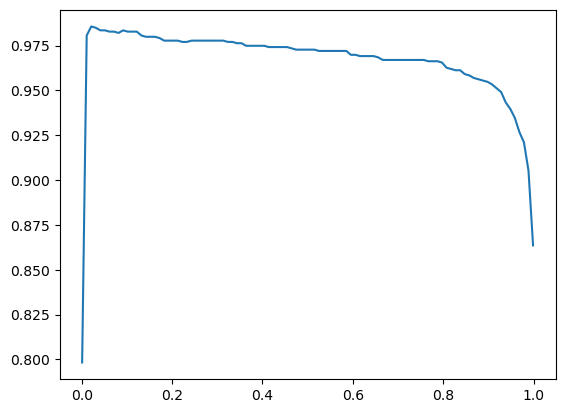

In [116]:
plt.plot(umbrales, accs)

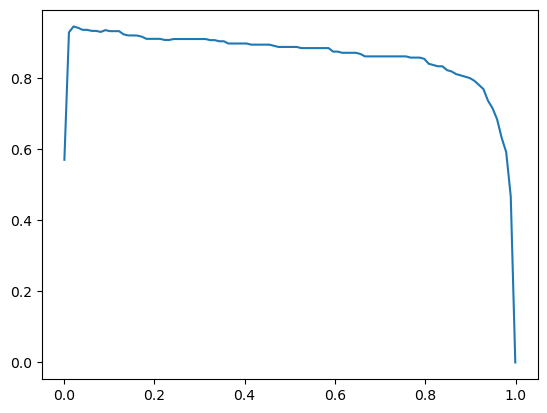

In [117]:
plt.plot(umbrales, f1_scores)

In [151]:
umbrales[np.argmax(f1_scores)]

0.021161616161616163

In [162]:
# Evaluación de textos individual
def input_and_evaluate_text(msg, umbral):
    texto_random = msg
    test_sequences_random = tok.texts_to_sequences(texto_random)
    test_sequences_matrix_random = sequence.pad_sequences(test_sequences_random,maxlen=max_len)
    texto_random = np.matrix(test_sequences_matrix_random[:,-1])

    prediction = model.predict(texto_random)

    if prediction > umbral:
        out = 'Spam'
    elif prediction <= umbral:
        out = 'Ham'
    
    return out

In [163]:
msg = 'Hi dear !!! please call me back whenever you want, we need to schedule the trip and we are getting out of time, see ya !'
input_and_evaluate_text(msg, umbrales[np.argmax(f1_scores)])

1/1 [==============================] - 0s 24ms/step


'Ham'

In [183]:
msg = "Hi, how r u? the guys are thinking'bout going for some beers and pizzas tonight"
input_and_evaluate_text(msg, umbrales[np.argmax(f1_scores)])

1/1 [==============================] - 0s 27ms/step


'Ham'

In [175]:
msg = "Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's"
input_and_evaluate_text(msg, umbrales[np.argmax(f1_scores)])

1/1 [==============================] - 0s 28ms/step


'Spam'

In [177]:
msg = "U R selected to be one of the mobile winnes of the month"
input_and_evaluate_text(msg, umbrales[np.argmax(f1_scores)])

1/1 [==============================] - 0s 25ms/step


'Spam'